# Exercice 7 — Classification binaire

In [76]:
import numpy as np

import pandas as pd

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics  import ConfusionMatrixDisplay , classification_report , confusion_matrix , precision_score , recall_score

import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score


### Generation du dataset

In [77]:
n = 500

df = pd.DataFrame({

    "age": np.random.randint(18, 76, n),

    "revenu_annuel": np.random.normal(

        loc=40000,

        scale=12000,

        size=n

    ).clip(10000, 100000).round(0),

    "anciennete_client_mois": np.random.randint(0, 241, n),

    "nb_produits_actuels": np.random.randint(0, 7, n),

    "score_credit": np.random.uniform(300, 850, n).round(0)
})

credit_norm = (df["score_credit"] - 300) / (850 - 300)

anciennete_norm = (

    df["anciennete_client_mois"] / 240

)

score_souscription = (

    0.6 * credit_norm

    + 0.4 * anciennete_norm

)

seuil = score_souscription.quantile(0.70)

df["a_souscrit"] = np.where(

    score_souscription >= seuil,

    "oui",
    
    "non"
)


In [78]:
df

,age,revenu_annuel,anciennete_client_mois,nb_produits_actuels,score_credit,a_souscrit
0,47,46097.0,170,2,334.0,non
1,66,48058.0,130,6,306.0,non
2,41,52665.0,52,3,441.0,non
3,24,40186.0,109,2,391.0,non
4,67,57432.0,14,4,835.0,oui
...,...,...,...,...,...,...
495,30,42038.0,106,4,364.0,non
496,36,64271.0,169,2,545.0,non
497,37,80810.0,23,0,498.0,non
498,28,46821.0,179,6,733.0,oui


### Encodage de la variable "a_souscrit"

In [79]:
encoder =  LabelEncoder()

df["a_souscrit"] =  encoder.fit_transform(df["a_souscrit"])

df

,age,revenu_annuel,anciennete_client_mois,nb_produits_actuels,score_credit,a_souscrit
0,47,46097.0,170,2,334.0,0
1,66,48058.0,130,6,306.0,0
2,41,52665.0,52,3,441.0,0
3,24,40186.0,109,2,391.0,0
4,67,57432.0,14,4,835.0,1
...,...,...,...,...,...,...
495,30,42038.0,106,4,364.0,0
496,36,64271.0,169,2,545.0,0
497,37,80810.0,23,0,498.0,0
498,28,46821.0,179,6,733.0,1


### Separation du train et du test

In [80]:
x = df.drop("a_souscrit",axis=1)

y =  df["a_souscrit"]

x_train , x_test , y_train , y_test = train_test_split(x, y, test_size=0.25) 

### Entraînement d'un model de LogisticRegression

In [81]:
model = LogisticRegression(max_iter=1000)

model.fit(x_train,y_train)

model.score(x_train,y_train)

pred = model.predict(x_test)

model.score(x_test,y_test)


0.992

### Affichage de la matrice de confusion

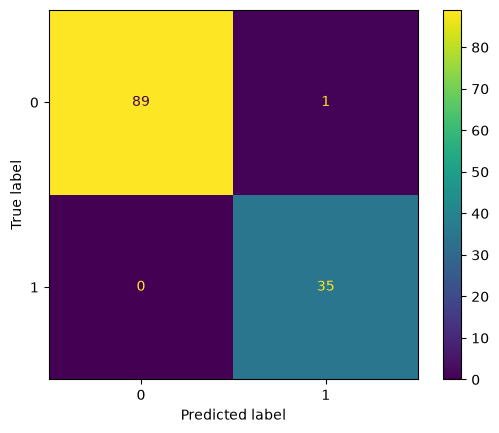

In [82]:
cm = confusion_matrix(y_test , pred ,labels=model.classes_)

mat_conf =  ConfusionMatrixDisplay(confusion_matrix=cm , display_labels=model.classes_)

mat_conf.plot()

### Affichage du rapport de classification

In [83]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99        90
           1       0.97      1.00      0.99        35

    accuracy                           0.99       125
   macro avg       0.99      0.99      0.99       125
weighted avg       0.99      0.99      0.99       125



### Tracage de la courbe ROC avec l'AUC affichée dans la légende

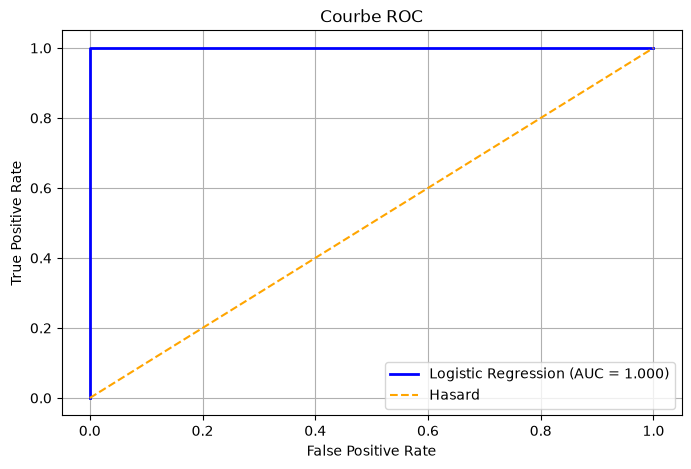

In [84]:
y_proba = model.predict_proba(x_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba,
    pos_label=1
)

auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    color="blue",
    linewidth=2,
    label=f"Logistic Regression (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="orange",
    label="Hasard"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Courbe ROC")

plt.legend()

plt.grid()

### Prédictions avec 3 seuils différents

In [86]:

seuils = [0.3, 0.5, 0.7]

resultats = []

for seuil in seuils:

    y_pred = (y_proba >= seuil).astype(int)

    precision = precision_score(y_test, y_pred)

    recall = recall_score(y_test, y_pred)

    resultats.append({

        "seuil": seuil,

        "precision": precision,
        
        "recall": recall
    })

df_resultats = pd.DataFrame(resultats)

print(df_resultats.round(3))

   seuil  precision  recall
0    0.3      0.972     1.0
1    0.5      0.972     1.0
2    0.7      0.972     1.0
